In [2]:
print("E-Commerce Sales Analysis")
print("Project 1: Data Understanding and Exploratory Data Analysis")

E-Commerce Sales Analysis
Project 1: Data Understanding and Exploratory Data Analysis


In [4]:
import pandas as pd
from pathlib import Path

data_path = Path("Online Retail.xlsx")
df = pd.read_excel(data_path)
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null values:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumerical summary:")
display(df.describe().round(2))

Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types and non-null values:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Un

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.00,541909,541909.00,406829.00
mean,9.55,2011-07-04 13:34:57.156386,4.61,15287.69
min,-80995.00,2010-12-01 08:26:00,-11062.06,12346.00
25%,1.00,2011-03-28 11:34:00,1.25,13953.00
50%,3.00,2011-07-19 17:17:00,2.08,15152.00
75%,10.00,2011-10-19 11:27:00,4.13,16791.00
max,80995.00,2011-12-09 12:50:00,38970.00,18287.00
std,218.08,NaN,96.76,1713.60


In [7]:
sales = df.drop_duplicates().copy()
sales = sales.dropna(subset=["Description"])

sales_all = sales.copy()
sales = sales.dropna(subset=["CustomerID"]).copy()

sales["InvoiceNo"] = sales["InvoiceNo"].astype(str)
sales["IsCancelled"] = sales["InvoiceNo"].str.startswith("C")
sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]

sales_clean = sales[
    (~sales["IsCancelled"])
    & (sales["Quantity"] > 0)
    & (sales["UnitPrice"] > 0)
].copy()

sales_clean["YearMonth"] = (
    sales_clean["InvoiceDate"].dt.to_period("M").astype(str)
)
sales_clean["Weekday"] = sales_clean["InvoiceDate"].dt.day_name()

print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(sales_clean))
print("Duplicate rows remaining:", sales_clean.duplicated().sum())
print("Missing customer IDs in original data:", df["CustomerID"].isna().sum())

Rows before cleaning: 541909
Rows after cleaning: 392692
Duplicate rows remaining: 0
Missing customer IDs in original data: 135080


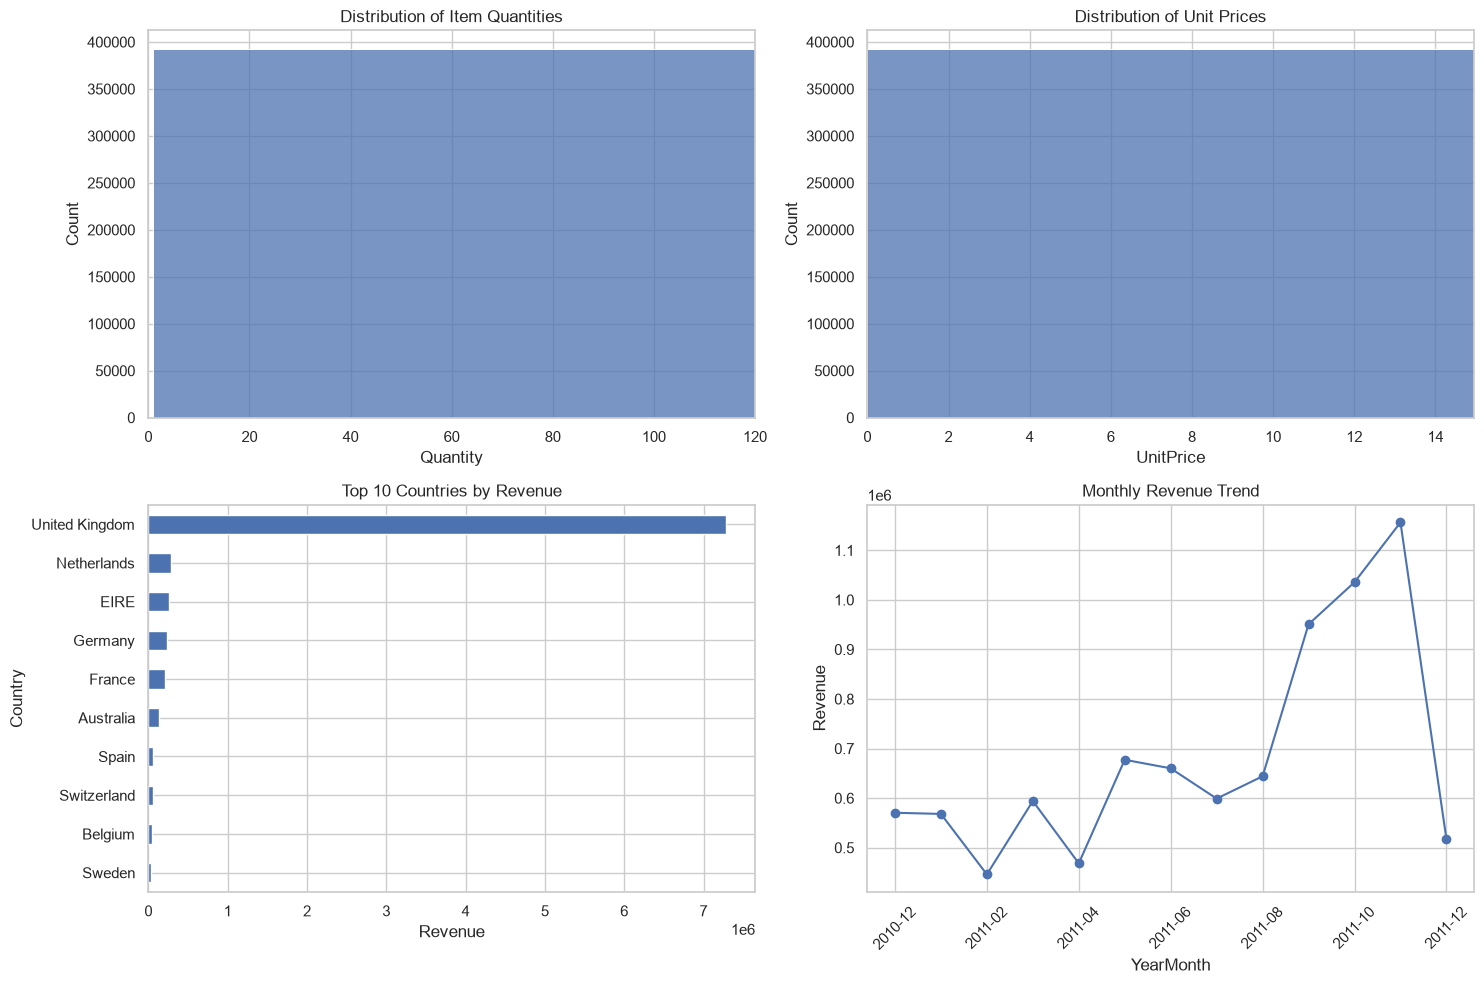

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.histplot(data=sales_clean, x="Quantity", bins=50, ax=axes[0, 0])
axes[0, 0].set_xlim(0, sales_clean["Quantity"].quantile(0.99))
axes[0, 0].set_title("Distribution of Item Quantities")

sns.histplot(data=sales_clean, x="UnitPrice", bins=50, ax=axes[0, 1])
axes[0, 1].set_xlim(0, sales_clean["UnitPrice"].quantile(0.99))
axes[0, 1].set_title("Distribution of Unit Prices")

top_countries = (
    sales_clean.groupby("Country")["Revenue"]
    .sum()
    .nlargest(10)
    .sort_values()
)
top_countries.plot(kind="barh", ax=axes[1, 0])
axes[1, 0].set_title("Top 10 Countries by Revenue")
axes[1, 0].set_xlabel("Revenue")

monthly_revenue = sales_clean.groupby("YearMonth")["Revenue"].sum()
monthly_revenue.plot(kind="line", marker="o", ax=axes[1, 1])
axes[1, 1].set_title("Monthly Revenue Trend")
axes[1, 1].set_ylabel("Revenue")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

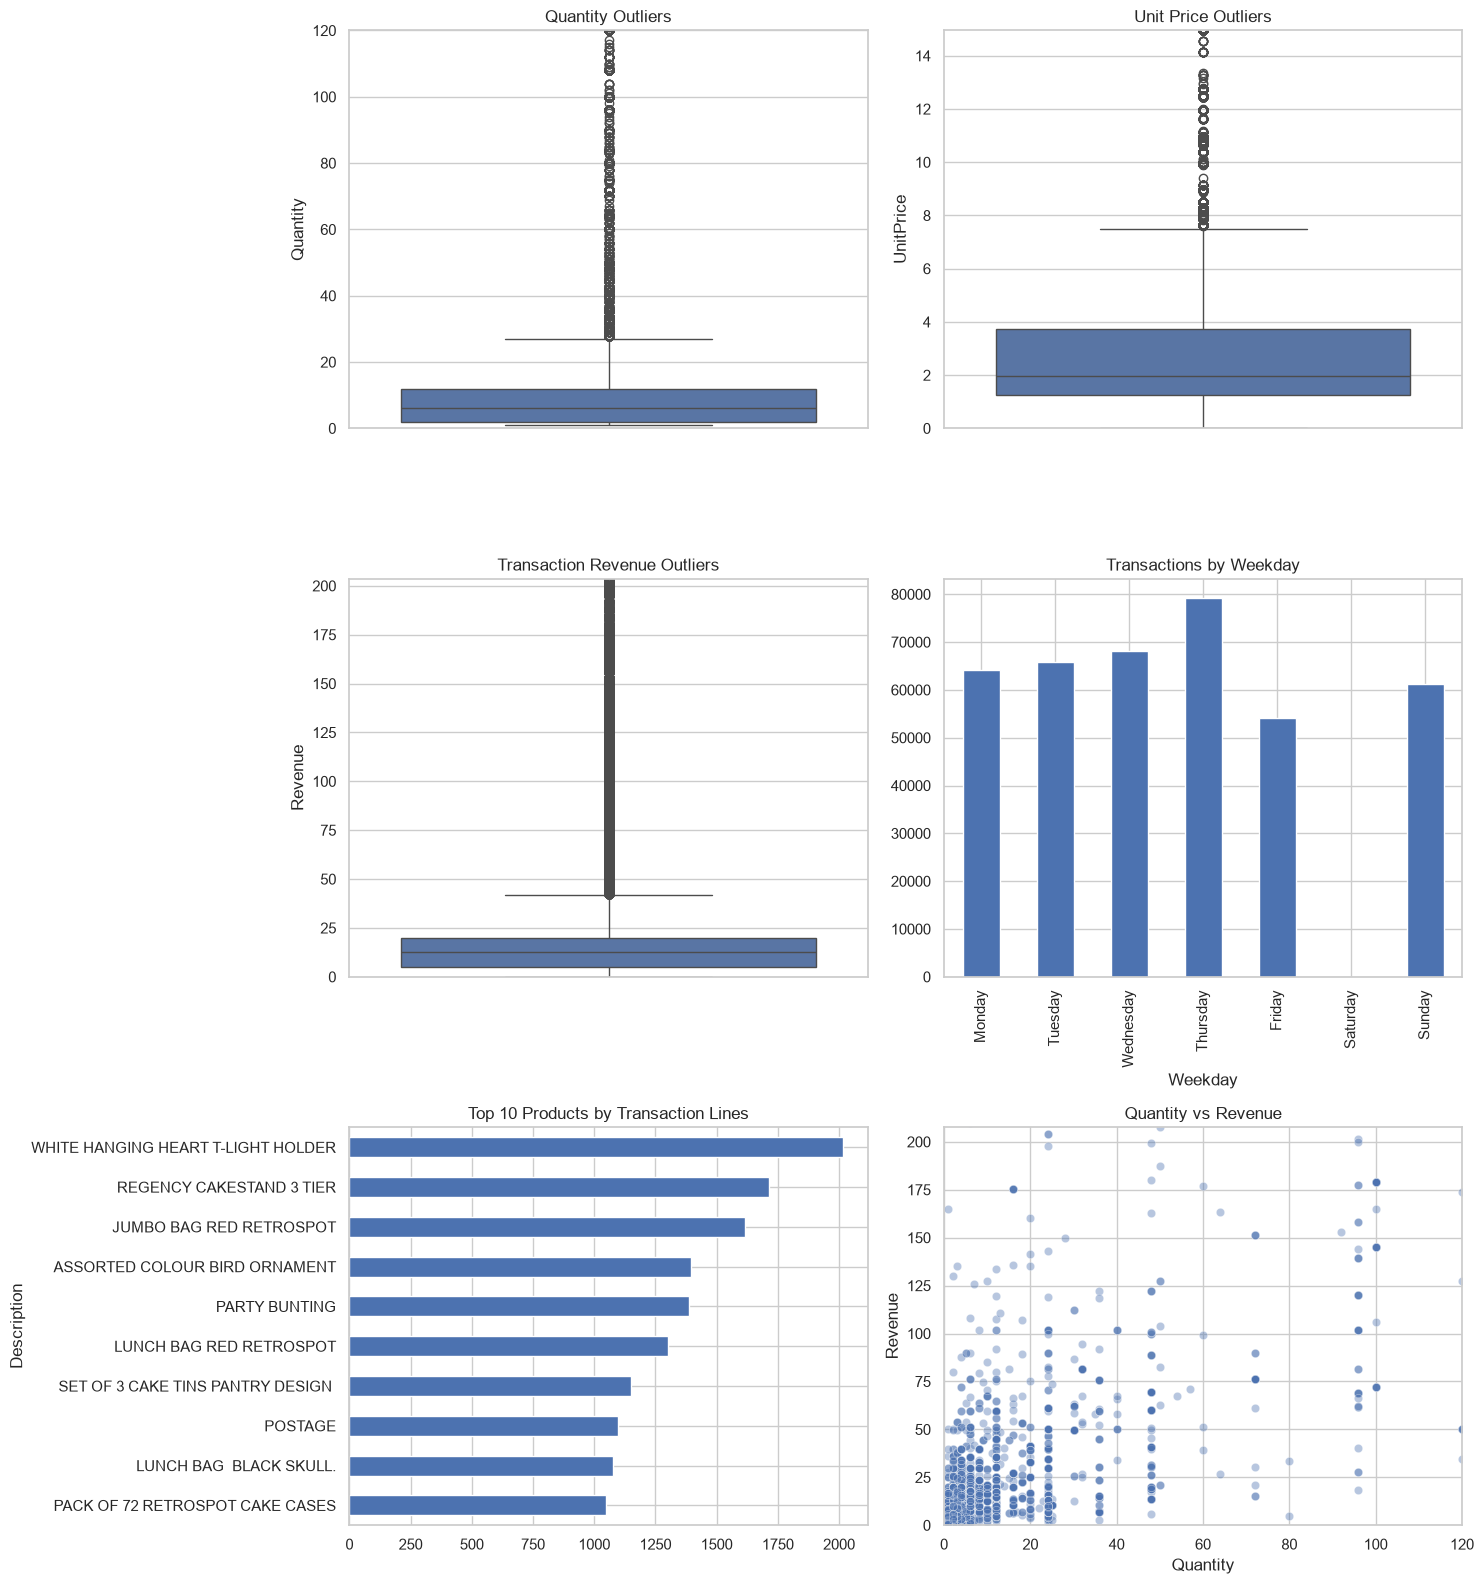

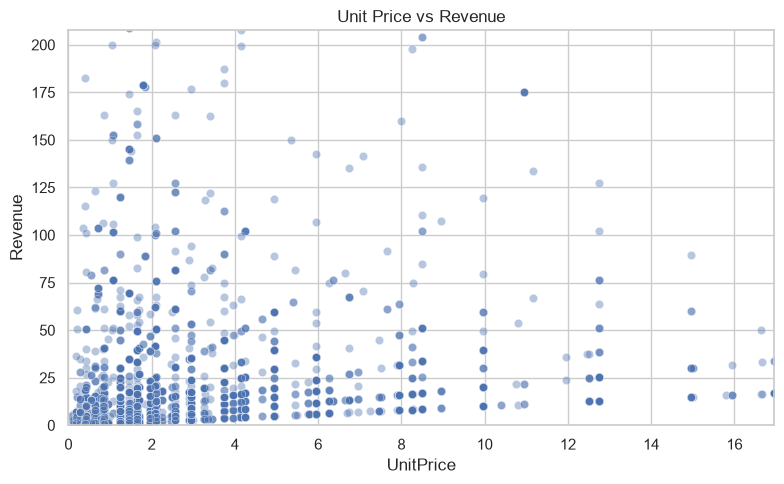

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(15, 16))

sns.boxplot(data=sales_clean, y="Quantity", ax=axes[0, 0])
axes[0, 0].set_ylim(0, sales_clean["Quantity"].quantile(0.99))
axes[0, 0].set_title("Quantity Outliers")

sns.boxplot(data=sales_clean, y="UnitPrice", ax=axes[0, 1])
axes[0, 1].set_ylim(0, sales_clean["UnitPrice"].quantile(0.99))
axes[0, 1].set_title("Unit Price Outliers")

sns.boxplot(data=sales_clean, y="Revenue", ax=axes[1, 0])
axes[1, 0].set_ylim(0, sales_clean["Revenue"].quantile(0.99))
axes[1, 0].set_title("Transaction Revenue Outliers")

sales_clean["Weekday"].value_counts().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
).plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Transactions by Weekday")

top_products = sales_clean["Description"].value_counts().head(10)
top_products.sort_values().plot(kind="barh", ax=axes[2, 0])
axes[2, 0].set_title("Top 10 Products by Transaction Lines")

sample = sales_clean.sample(min(5000, len(sales_clean)), random_state=42)
sns.scatterplot(data=sample, x="Quantity", y="Revenue", alpha=0.4, ax=axes[2, 1])
axes[2, 1].set_xlim(0, sample["Quantity"].quantile(0.99))
axes[2, 1].set_ylim(0, sample["Revenue"].quantile(0.99))
axes[2, 1].set_title("Quantity vs Revenue")

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=sample, x="UnitPrice", y="Revenue", alpha=0.4
)
plt.xlim(0, sample["UnitPrice"].quantile(0.99))
plt.ylim(0, sample["Revenue"].quantile(0.99))
plt.title("Unit Price vs Revenue")
plt.tight_layout()
plt.show()

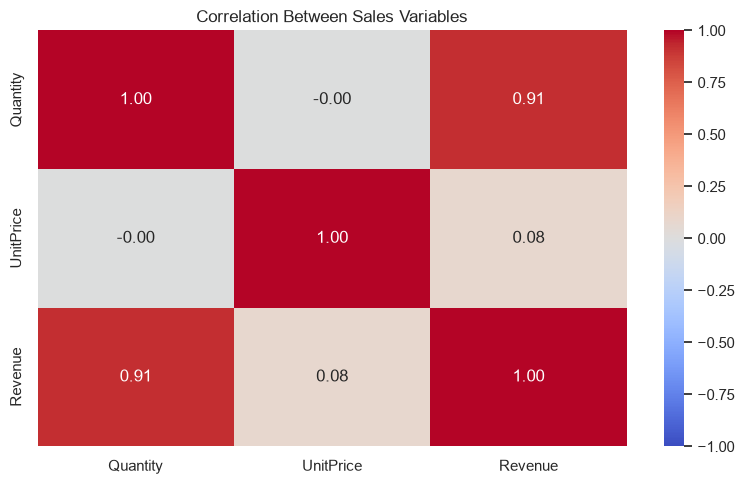

Total revenue: £8,887,208.89
Completed invoices: 18,532
Unique customers: 4,338
Average invoice value: £479.56

Top 5 products by revenue:


Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
Name: Revenue, dtype: float64


Top 5 countries by revenue:


Country
United Kingdom    7285024.64
Netherlands        285446.34
EIRE               265262.46
Germany            228678.40
France             208934.31
Name: Revenue, dtype: float64

In [10]:
numeric_cols = ["Quantity", "UnitPrice", "Revenue"]

plt.figure(figsize=(8, 5))
sns.heatmap(
    sales_clean[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Between Sales Variables")
plt.tight_layout()
plt.show()

total_revenue = sales_clean["Revenue"].sum()
total_invoices = sales_clean["InvoiceNo"].nunique()
total_customers = sales_clean["CustomerID"].nunique()
average_order_value = sales_clean.groupby("InvoiceNo")["Revenue"].sum().mean()

print(f"Total revenue: £{total_revenue:,.2f}")
print(f"Completed invoices: {total_invoices:,}")
print(f"Unique customers: {total_customers:,}")
print(f"Average invoice value: £{average_order_value:,.2f}")

print("\nTop 5 products by revenue:")
display(
    sales_clean.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .round(2)
)

print("\nTop 5 countries by revenue:")
display(
    sales_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .round(2)
)

In [11]:
print("Monthly revenue")
display(
    sales_clean.groupby("YearMonth")["Revenue"]
    .sum().sort_values(ascending=False).head(5).round(2)
)

print("Top countries excluding the UK")
display(
    sales_clean[sales_clean["Country"] != "United Kingdom"]
    .groupby("Country")["Revenue"]
    .sum().sort_values(ascending=False).head(5).round(2)
)

print("Highest-spending customers")
display(
    sales_clean.groupby("CustomerID")["Revenue"]
    .sum().sort_values(ascending=False).head(5).round(2)
)

print("Cancellation rate among invoice lines")
print(f"{sales['IsCancelled'].mean() * 100:.2f}%")

print("Revenue by weekday")
display(
    sales_clean.groupby("Weekday")["Revenue"]
    .sum().sort_values(ascending=False).round(2)
)

Monthly revenue


YearMonth
2011-11    1156205.61
2011-10    1035642.45
2011-09     950690.20
2011-05     677355.15
2011-06     660046.05
Name: Revenue, dtype: float64

Top countries excluding the UK


Country
Netherlands    285446.34
EIRE           265262.46
Germany        228678.40
France         208934.31
Australia      138453.81
Name: Revenue, dtype: float64

Highest-spending customers


CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
Name: Revenue, dtype: float64

Cancellation rate among invoice lines
2.21%
Revenue by weekday


Weekday
Thursday     1973015.73
Tuesday      1697733.80
Wednesday    1584283.83
Friday       1483080.81
Monday       1363604.40
Sunday        785490.32
Name: Revenue, dtype: float64

In [12]:
findings = pd.DataFrame({
    "Finding": [
        "Total revenue",
        "Completed invoices",
        "Unique customers",
        "Average invoice value",
        "Top month by revenue",
        "Top non-UK country",
        "Cancellation rate"
    ],
    "Result": [
        f"£{sales_clean['Revenue'].sum():,.2f}",
        f"{sales_clean['InvoiceNo'].nunique():,}",
        f"{sales_clean['CustomerID'].nunique():,}",
        f"£{sales_clean.groupby('InvoiceNo')['Revenue'].sum().mean():,.2f}",
        sales_clean.groupby("YearMonth")["Revenue"].sum().idxmax(),
        sales_clean[sales_clean["Country"] != "United Kingdom"].groupby("Country")["Revenue"].sum().idxmax(),
        f"{sales['IsCancelled'].mean() * 100:.2f}%"
    ]
})

display(findings)

,Finding,Result
0,Total revenue,"£8,887,208.89"
1,Completed invoices,"18,532"
2,Unique customers,"4,338"
3,Average invoice value,£479.56
4,Top month by revenue,2011-11
5,Top non-UK country,Netherlands
6,Cancellation rate,2.21%


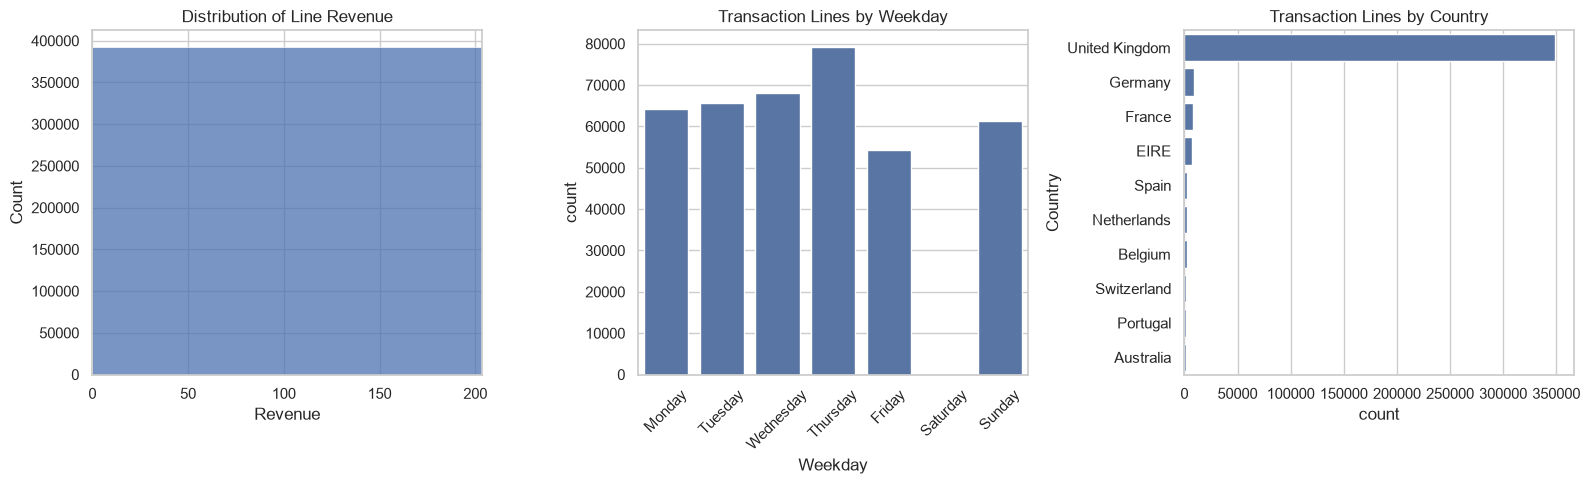

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(data=sales_clean, x="Revenue", bins=50, ax=axes[0])
axes[0].set_xlim(0, sales_clean["Revenue"].quantile(0.99))
axes[0].set_title("Distribution of Line Revenue")

sns.countplot(
    data=sales_clean,
    x="Weekday",
    order=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
    ax=axes[1]
)
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_title("Transaction Lines by Weekday")

top_countries = sales_clean["Country"].value_counts().head(10).index
sns.countplot(
    data=sales_clean[sales_clean["Country"].isin(top_countries)],
    y="Country",
    order=sales_clean["Country"].value_counts().head(10).index,
    ax=axes[2]
)
axes[2].set_title("Transaction Lines by Country")

plt.tight_layout()
plt.show()